# Machine Learning Analysis of stock Market Data clustering and time series forecasting approach

# Lets import libraries

In [5]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt 

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score
from sklearn.metrics import mean_absolute_error, mean_squared_error

from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX

# Set default figure size
plt.rcParams["figure.figsize"] = (12, 6)

In [6]:
import yfinance as yf

# Choose 10 stocks
stocks = ["NFLX", "ORCL", "IBM", "QCOM", "ADBE", "INTU", "CSCO", "TXN", "AMD", "CRM"]

for stock in stocks:
    df = yf.download(stock, start="2016-01-01", end="2025-12-31")
    df.reset_index(inplace=True)   # make Date a normal column 
    df.to_csv(f"{stock}.csv", index=False)
    print(f"{stock} saved")

print("Download complete!")

[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed


NFLX saved
ORCL saved


[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed


IBM saved
QCOM saved


[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed


ADBE saved
INTU saved


[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed


CSCO saved
TXN saved


[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed

AMD saved
CRM saved
Download complete!


 # Load all CSV files

In [7]:
# list of selscted stock tickers
stock = ["NFLX", "ORCL", "IBM", "QCOM", "ADBE", "INTU", "CSCO", "TXN", "AMD", "CRM"]

# Creat an empty list to store all stock data
all_data = []

for stock in stock:
     # Read each CSV file / CSV
    df = pd.read_csv(f"{stock}.csv")
    # Remove the first two incorrect rows 
    df = df.iloc[2:].copy()

    df.rename(columns={"Price": "Date"}, inplace=True)

    #Add stock name as a new column
    df["Stock"] = stock

    #Store cleaned file in the kist
    all_data.append(df)

#combine all stock data into one dataframe
combined_df = pd.concat(all_data, ignore_index=True)

#Preview the raw combined data
print(combined_df.head())
print(combined_df.shape)
print(combined_df.columns)


         Date               Close                High                 Low  \
0  2016-01-05  10.765999794006348  11.057999610900879  10.585000038146973   
1  2016-01-06  11.767999649047852  11.791000366210938  10.496000289916992   
2  2016-01-07  11.456000328063965  12.218000411987305  11.229000091552734   
3  2016-01-08  11.138999938964844  11.772000312805176  11.109999656677246   
4  2016-01-11  11.496999740600586  11.678999900817871  11.119999885559082   

                 Open     Volume Stock  
0  11.045000076293945  176646000  NFLX  
1  10.529000282287598  330457000  NFLX  
2   11.63599967956543  336367000  NFLX  
3  11.633000373840332  180671000  NFLX  
4  11.213000297546387  219204000  NFLX  
(25120, 7)
Index(['Date', 'Close', 'High', 'Low', 'Open', 'Volume', 'Stock'], dtype='str')


In [8]:
# Remove extra space from column names 
combined_df.columns = combined_df.columns.str.strip()

# Convert Date column to datetime format
combined_df["Date"] = pd.to_datetime(combined_df["Date"], errors="coerce")

# Convert numeric columns to numeric type
numeric_cols = ["Open", "High", "Low", "Close", "Volume"]
for col in numeric_cols:
        combined_df[col] = pd.to_numeric(combined_df[col], errors="coerce")
    
# Remove rows with missing Date or Close values/ 
combined_df = combined_df.dropna(subset=["Date", "Close"])

# Sort data by Stock and Date /
combined_df = combined_df.sort_values(by=["Stock", "Date"]).reset_index(drop=True)

#check missing values and preview cleaned data 
print (combined_df.isnull().sum())
print (combined_df.head())
print (combined_df.info())

Date      0
Close     0
High      0
Low       0
Open      0
Volume    0
Stock     0
dtype: int64
        Date      Close       High        Low       Open   Volume Stock
0 2016-01-05  92.339996  92.849998  91.410004  92.010002  1821300  ADBE
1 2016-01-06  91.019997  91.500000  90.239998  91.099998  1674000  ADBE
2 2016-01-07  89.110001  91.400002  88.709999  89.400002  2717800  ADBE
3 2016-01-08  87.849998  89.989998  87.629997  89.680000  2263400  ADBE
4 2016-01-11  89.379997  89.800003  87.839996  88.070000  2362200  ADBE
<class 'pandas.DataFrame'>
RangeIndex: 25120 entries, 0 to 25119
Data columns (total 7 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   Date    25120 non-null  datetime64[us]
 1   Close   25120 non-null  float64       
 2   High    25120 non-null  float64       
 3   Low     25120 non-null  float64       
 4   Open    25120 non-null  float64       
 5   Volume  25120 non-null  int64         
 6   Stock   25120 non

 # Create return column

In [9]:
# Calculate daily percentgw return for each stock
combined_df["Return"] = combined_df.groupby("Stock")["Close"].pct_change()
#preview Date, stock, close and return columns 
print (combined_df[["Date", "Stock", "Close", "Return"]].head(10))

        Date Stock      Close    Return
0 2016-01-05  ADBE  92.339996       NaN
1 2016-01-06  ADBE  91.019997 -0.014295
2 2016-01-07  ADBE  89.110001 -0.020984
3 2016-01-08  ADBE  87.849998 -0.014140
4 2016-01-11  ADBE  89.379997  0.017416
5 2016-01-12  ADBE  89.820000  0.004923
6 2016-01-13  ADBE  88.300003 -0.016923
7 2016-01-14  ADBE  89.800003  0.016988
8 2016-01-15  ADBE  89.169998 -0.007016
9 2016-01-19  ADBE  89.180000  0.000112


# Initial eploratory data analysis

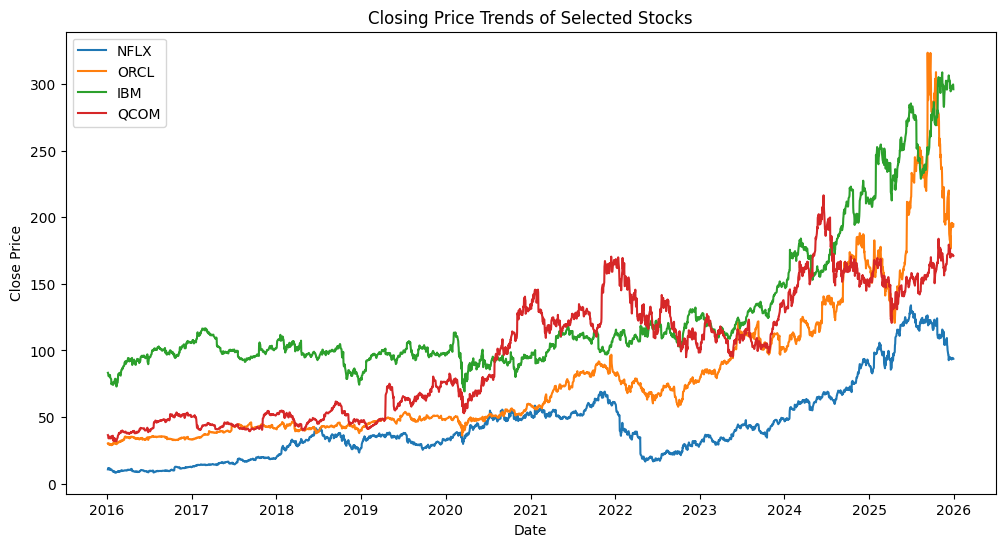

In [10]:
# Plot closing price trends for selected stocks
plt.figure(figsize=(12, 6))

for stock in ["NFLX", "ORCL", "IBM", "QCOM"]:
    temp= combined_df[combined_df["Stock"] ==stock]
    plt.plot(temp["Date"],temp["Close"], label=stock)

plt.title("Closing Price Trends of Selected Stocks")
plt.xlabel("Date")
plt.ylabel("Close Price")
plt.legend()
plt.show()

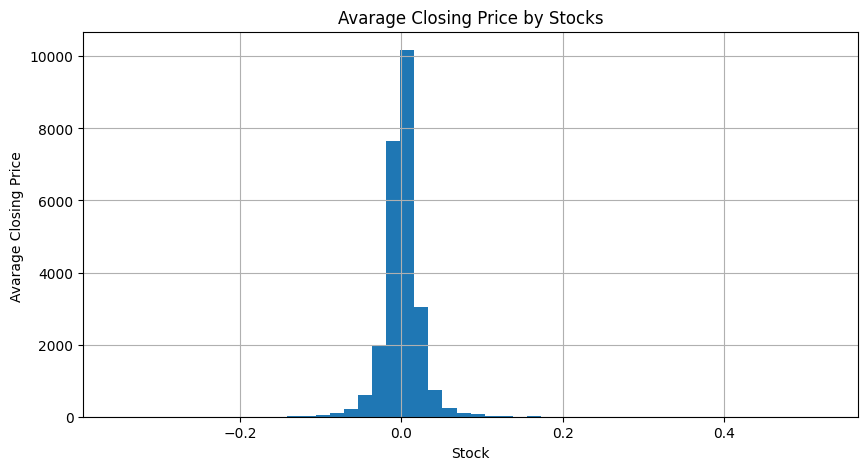

In [11]:
# Plot histogram of daily returns
plt.figure(figsize=(10, 5))
combined_df["Return"].dropna().hist(bins=50)
plt.title("Avarage Closing Price by Stocks")
plt.xlabel("Stock")
plt.ylabel("Avarage Closing Price ")
plt.show()

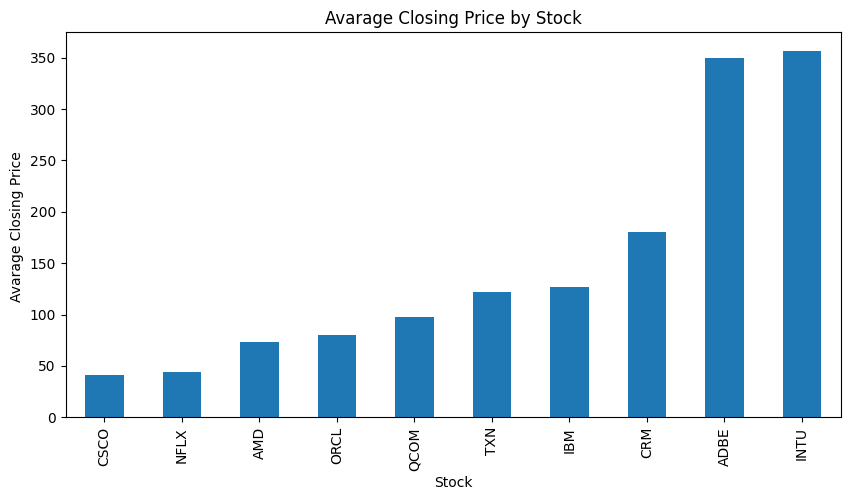

In [12]:
# Calculate average closing price by stock/
avg_close = combined_df.groupby("Stock")["Close"].mean().sort_values()

#Plot average close price
plt.figure(figsize=(10, 5))
avg_close.plot(kind="bar")

plt.title("Avarage Closing Price by Stock")
plt.xlabel("Stock")
plt.ylabel("Avarage Closing Price ")
plt.show()

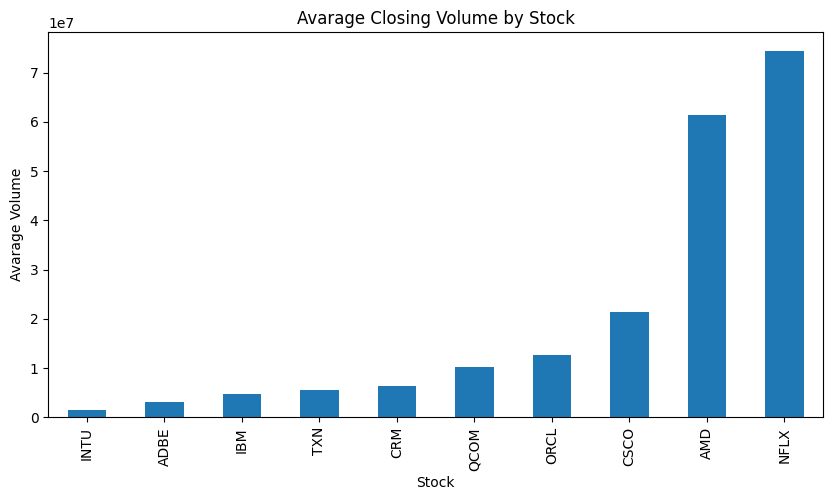

In [13]:
# Calculate average trading volume by stock/
avg_volume = combined_df.groupby("Stock")["Volume"].mean().sort_values()

#Plot average volume
plt.figure(figsize=(10, 5))
avg_volume.plot(kind="bar")

plt.title("Avarage Closing Volume by Stock")
plt.xlabel("Stock")
plt.ylabel("Avarage Volume")
plt.show()

In [14]:
# Aggregate importan features for each stock
features = combined_df.groupby("Stock").agg(
    Avg_Return=("Return", "mean"),
    Volatility=("Return", "std"),
    Avg_Volume=("Volume", "mean"),
    Avg_Price=("Close", "mean"),
    Max_Price=("Close", "max"),
    Min_Price=("Close", "min")
)
# Create price range feature / 
features["Price_Range"] = features["Max_Price"] - features["Min_Price"]

#drop missing values if any 
features = features.dropna()

#Preview feature dataset
print(features)

       Avg_Return  Volatility    Avg_Volume   Avg_Price   Max_Price  \
Stock                                                                 
ADBE     0.000762    0.021275  3.060247e+06  349.744482  688.369995   
AMD      0.002414    0.037262  6.141630e+07   73.489072  264.329987   
CRM      0.000741    0.022029  6.361425e+06  180.134327  362.581329   
CSCO     0.000675    0.015798  2.146152e+07   40.651720   78.791313   
IBM      0.000627    0.015599  4.813646e+06  126.763184  308.691681   
INTU     0.001005    0.019990  1.512440e+06  357.044861  794.713684   
NFLX     0.001219    0.026435  7.448658e+07   43.607031  133.912994   
ORCL     0.000950    0.020785  1.264125e+07   80.049465  323.433746   
QCOM     0.000893    0.023629  1.019375e+07   97.459754  216.441895   
TXN      0.000757    0.018761  5.429512e+06  122.302941  214.117294   

       Min_Price  Price_Range  
Stock                          
ADBE   73.849998   614.519997  
AMD     1.800000   262.529987  
CRM    53.037502   

# Scale features

In [16]:
# Select only imput features for clustering
feature_cols = ["Avg_Return", "Volatility", "Avg_Volume", "Avg_Price", "Max_Price"]

# Standardize the features
scaler = StandardScaler()
Scaled_features = scaler.fit_transform(features[feature_cols])

# Convert scaled array to dataframe for inspection
scaled_df = pd.DataFrame(Scaled_features, index=features.index, columns=feature_cols)
print(scaled_df)

       Avg_Return  Volatility  Avg_Volume  Avg_Price  Max_Price
Stock                                                          
ADBE    -0.486406   -0.148749   -0.691783   1.836830   1.601081
AMD      2.825983    2.549741    1.672141  -0.667536  -0.339631
CRM     -0.528304   -0.021459   -0.558057   0.299246   0.110038
CSCO    -0.659327   -1.073246    0.053627  -0.965220  -1.188789
IBM     -0.755581   -1.106855   -0.620755  -0.184585  -0.136600
INTU     0.000532   -0.365658   -0.754482   1.903011   2.087786
NFLX     0.430298    0.722235    2.201599  -0.938429  -0.936513
ORCL    -0.107906   -0.231526   -0.303670  -0.608064  -0.069130
QCOM    -0.223595    0.248655   -0.402814  -0.450232  -0.558801
TXN     -0.495695   -0.573138   -0.595807  -0.225019  -0.569440


 # Choose number of clusters using elbow method

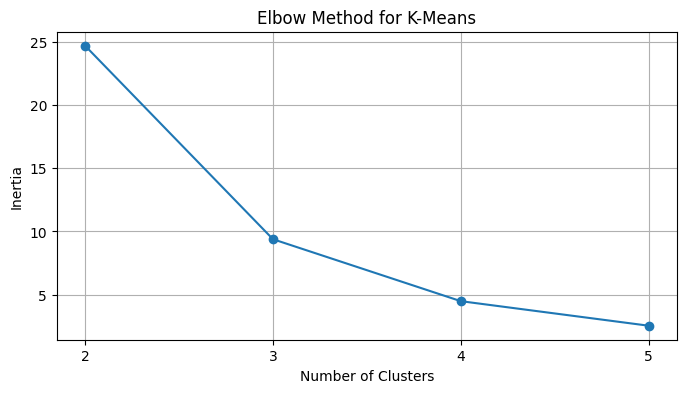

In [21]:
# Calculate interia values for different k values
inertia = []
k_values = range(2, 6)

for k in k_values:
    km = KMeans (n_clusters=k, random_state=42, n_init=10)
    km.fit(scaled_features)
    inertia.append(km.inertia_)

# Plot elbow method 
plt.figure(figsize=(8, 4))
plt.plot(k_values, inertia, marker="o")
plt.title("Elbow Method for K-Means")
plt.xlabel("Number of Clusters")
plt.ylabel("Inertia")
plt.xticks(k_values)
plt.grid(True)
plt.show()

 # K-Means clustering

In [23]:
# K-Means clustering 
kmeans = KMeans (n_clusters=3, random_state=42, n_init=10)
kmeans_labels = kmeans.fit_predict(scaled_features)

# Store K-means cluter labels
features["KMeans_Cluster"] = kmeans_labels

# View clutering results
print(features)

       Avg_Return  Volatility    Avg_Volume   Avg_Price   Max_Price  \
Stock                                                                 
ADBE     0.000762    0.021275  3.060247e+06  349.744482  688.369995   
AMD      0.002414    0.037262  6.141630e+07   73.489072  264.329987   
CRM      0.000741    0.022029  6.361425e+06  180.134327  362.581329   
CSCO     0.000675    0.015798  2.146152e+07   40.651720   78.791313   
IBM      0.000627    0.015599  4.813646e+06  126.763184  308.691681   
INTU     0.001005    0.019990  1.512440e+06  357.044861  794.713684   
NFLX     0.001219    0.026435  7.448658e+07   43.607031  133.912994   
ORCL     0.000950    0.020785  1.264125e+07   80.049465  323.433746   
QCOM     0.000893    0.023629  1.019375e+07   97.459754  216.441895   
TXN      0.000757    0.018761  5.429512e+06  122.302941  214.117294   

       Min_Price  Price_Range  KMeans_Cluster  
Stock                                          
ADBE   73.849998   614.519997               2  
AMD

# Agglomerative clustering

In [25]:
# Aplly Agglomerative clustering 
agg = AgglomerativeClustering (n_clusters=3)
agg_labels = agg.fit_predict(scaled_features)

#Store Agglomerative cluster labels
features["Agglomerative_Cluster"] = agg_labels

#view clustering results
print(features)

       Avg_Return  Volatility    Avg_Volume   Avg_Price   Max_Price  \
Stock                                                                 
ADBE     0.000762    0.021275  3.060247e+06  349.744482  688.369995   
AMD      0.002414    0.037262  6.141630e+07   73.489072  264.329987   
CRM      0.000741    0.022029  6.361425e+06  180.134327  362.581329   
CSCO     0.000675    0.015798  2.146152e+07   40.651720   78.791313   
IBM      0.000627    0.015599  4.813646e+06  126.763184  308.691681   
INTU     0.001005    0.019990  1.512440e+06  357.044861  794.713684   
NFLX     0.001219    0.026435  7.448658e+07   43.607031  133.912994   
ORCL     0.000950    0.020785  1.264125e+07   80.049465  323.433746   
QCOM     0.000893    0.023629  1.019375e+07   97.459754  216.441895   
TXN      0.000757    0.018761  5.429512e+06  122.302941  214.117294   

       Min_Price  Price_Range  KMeans_Cluster  Agglomerative_Cluster  
Stock                                                                 
ADBE 